# Tutorial 1: Pengenalan Matplotlib

**Tujuan Pembelajaran:**
- Memahami dasar-dasar visualisasi dengan Matplotlib
- Membuat line plot, bar chart, dan scatter plot
- Melakukan kustomisasi grafik (label, title, legend, warna)
- Membuat subplots dan dashboard

**Dataset:** `sales_data.csv` - Data penjualan berbagai produk

---

## 📖 Daftar Isi

1. Setup dan Import Libraries
2. Load dan Eksplorasi Data
3. Line Plot - Grafik Garis
4. Bar Chart - Diagram Batang
5. Scatter Plot - Plot Sebaran
6. Kustomisasi Lanjutan
7. Tips dan Best Practices

---

## Apa itu Matplotlib?

Matplotlib adalah library Python yang paling populer untuk membuat visualisasi data. Dengan Matplotlib, kita bisa membuat berbagai jenis grafik seperti line plot, bar chart, scatter plot, histogram, dan masih banyak lagi.

**Analogi sederhana:** Matplotlib seperti kanvas dan kuas untuk melukis grafik. Anda bisa menggambar apa saja yang Anda mau!

## 1. Setup dan Import Libraries

Pertama-tama, import library yang diperlukan:

In [1]:
# Import library yang diperlukan
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Konfigurasi untuk tampilan yang lebih baik
plt.style.use('default')
%matplotlib inline

print("✅ Library berhasil diimport!")
print(f"📊 Matplotlib versi: {plt.matplotlib.__version__}")

✅ Library berhasil diimport!
📊 Matplotlib versi: 3.8.4


## 2. Load dan Eksplorasi Data

Mari kita load dataset `sales_data.csv` yang berisi data penjualan berbagai produk:

In [2]:
# Load dataset
df = pd.read_csv('sales_data.csv')

# Melihat beberapa baris pertama
print("📋 Preview Data:")
print(df.head())
print(f"\n📊 Ukuran dataset: {df.shape[0]} baris, {df.shape[1]} kolom")
print(f"\n📂 Kolom-kolom: {', '.join(df.columns)}")

📋 Preview Data:
         Date     Product     Category  Quantity  Price  Revenue  \
0  2024-01-15      Laptop  Electronics         2  850.0   1700.0   
1  2024-01-16       Mouse  Electronics         5   25.0    125.0   
2  2024-01-17    Keyboard  Electronics         3   75.0    225.0   
3  2024-01-18     Monitor  Electronics         1  300.0    300.0   
4  2024-01-19  Headphones  Electronics         4  150.0    600.0   

   Customer_Age Gender Region  
0            28      M  North  
1            34      F  South  
2            25      M   East  
3            42      F   West  
4            31      M  North  

📊 Ukuran dataset: 50 baris, 9 kolom

📂 Kolom-kolom: Date, Product, Category, Quantity, Price, Revenue, Customer_Age, Gender, Region


In [3]:
# Informasi detail tentang dataset
print("ℹ️ Informasi Dataset:")
df.info()
print("\n" + "="*50)
print("\n📈 Statistik Deskriptif:")
print(df.describe())

ℹ️ Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          50 non-null     object 
 1   Product       50 non-null     object 
 2   Category      50 non-null     object 
 3   Quantity      50 non-null     int64  
 4   Price         50 non-null     float64
 5   Revenue       50 non-null     float64
 6   Customer_Age  50 non-null     int64  
 7   Gender        50 non-null     object 
 8   Region        50 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 3.6+ KB


📈 Statistik Deskriptif:
       Quantity       Price      Revenue  Customer_Age
count  50.00000   50.000000    50.000000       50.0000
mean    7.80000  106.030000   254.480000       31.9400
std     9.03056  178.453115   306.763103        6.9588
min     1.00000    1.500000    60.000000       19.0000
25%     2.00000   15.000000   100.000000

---

## 3. Line Plot - Grafik Garis

**Kapan menggunakan Line Plot?**
- Menampilkan tren data dari waktu ke waktu
- Membandingkan beberapa series data
- Menunjukkan perubahan kontinu

### 3.1 Line Plot Sederhana

Mari kita buat grafik revenue per kategori:

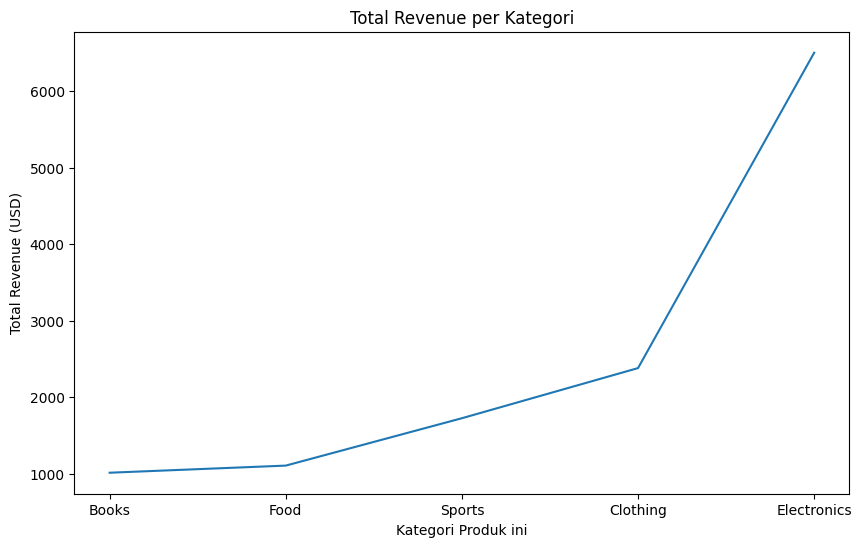


💰 Total Revenue per Kategori:
Category
Books          1013.0
Food           1106.0
Sports         1725.0
Clothing       2380.0
Electronics    6500.0
Name: Revenue, dtype: float64


In [ ]:
# Agregasi data: Total revenue per kategori
revenue_by_category = df.groupby('Category')['Revenue'].sum().sort_values()

# Membuat line plot sederhana
plt.figure(figsize=(10, 6))
plt.plot(revenue_by_category.index, revenue_by_category.values)

plt.title('Total Revenue per Kategori')
plt.xlabel('Kategori Produk')
plt.ylabel('Total Revenue (USD)')

plt.show()

print(f"\n💰 Total Revenue per Kategori:")
print(revenue_by_category)

### 3.2 Line Plot dengan Marker

Menambahkan marker membuat setiap titik data lebih jelas terlihat:

In [ ]:
# Line plot dengan marker
plt.figure(figsize=(10, 6))
plt.plot(revenue_by_category.index, 
         revenue_by_category.values,
         marker='o',           # Bentuk marker: 'o', 's', '^', 'D', '*'
         markersize=10,        # Ukuran marker
         linewidth=2,          # Ketebalan garis
         color='blue',         # Warna garis
         markerfacecolor='red', # Warna isi marker
         markeredgecolor='black', # Warna tepi marker
         markeredgewidth=2)    # Ketebalan tepi marker

plt.title('Total Revenue per Kategori (dengan Marker)', fontsize=14, fontweight='bold')
plt.xlabel('Kategori Produk', fontsize=12)
plt.ylabel('Total Revenue (USD)', fontsize=12)
plt.grid(True, alpha=0.3, linestyle='--')

plt.show()

### 3.3 Multiple Line Plots - Membandingkan Beberapa Data

Mari kita bandingkan penjualan berdasarkan region:

In [ ]:
# Konversi kolom Date ke datetime
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.to_period('M').astype(str)

# Data revenue per bulan untuk setiap region
revenue_by_month_region = df.groupby(['Month', 'Region'])['Revenue'].sum().unstack(fill_value=0)

# Multiple line plot
plt.figure(figsize=(12, 6))

for region in revenue_by_month_region.columns:
    plt.plot(revenue_by_month_region.index, 
             revenue_by_month_region[region],
             marker='o',
             linewidth=2,
             label=region)

plt.title('Tren Revenue Bulanan per Region', fontsize=14, fontweight='bold')
plt.xlabel('Bulan', fontsize=12)
plt.ylabel('Revenue (USD)', fontsize=12)
plt.legend(title='Region', loc='best')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

print("\n📊 Revenue per Bulan dan Region:")
print(revenue_by_month_region)

---

## 4. Bar Chart - Diagram Batang

**Kapan menggunakan Bar Chart?**
- Membandingkan nilai antar kategori
- Menampilkan ranking atau urutan
- Membandingkan beberapa grup data

### 4.1 Vertical Bar Chart (Bar Chart Vertikal)

In [ ]:
# Total quantity terjual per kategori
quantity_by_category = df.groupby('Category')['Quantity'].sum().sort_values(ascending=False)

# Bar chart vertikal
plt.figure(figsize=(10, 6))
bars = plt.bar(quantity_by_category.index, 
               quantity_by_category.values,
               color='skyblue',
               alpha=0.7,
               edgecolor='black',
               linewidth=1.5)

# Menambahkan nilai di atas setiap bar
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}',
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title('Total Quantity Terjual per Kategori', fontsize=14, fontweight='bold')
plt.xlabel('Kategori Produk', fontsize=12)
plt.ylabel('Total Quantity', fontsize=12)
plt.grid(True, alpha=0.3, axis='y')

plt.show()

print(f"\n📦 Total Quantity per Kategori:")
print(quantity_by_category)

### 4.2 Horizontal Bar Chart (Bar Chart Horizontal)

Bar chart horizontal bagus untuk label yang panjang:

In [ ]:
# Top 10 produk berdasarkan revenue
top_products = df.groupby('Product')['Revenue'].sum().nlargest(10).sort_values()

# Horizontal bar chart
plt.figure(figsize=(10, 8))
bars = plt.barh(top_products.index, 
                top_products.values,
                color='coral',
                alpha=0.8,
                edgecolor='black')

# Menambahkan nilai di ujung setiap bar
for i, bar in enumerate(bars):
    width = bar.get_width()
    plt.text(width, bar.get_y() + bar.get_height()/2.,
             f'${width:,.0f}',
             ha='left', va='center', fontsize=9, fontweight='bold')

plt.title('Top 10 Produk Berdasarkan Revenue', fontsize=14, fontweight='bold')
plt.xlabel('Total Revenue (USD)', fontsize=12)
plt.ylabel('Produk', fontsize=12)
plt.grid(True, alpha=0.3, axis='x')

plt.show()

print(f"\n🏆 Top 10 Produk:")
print(top_products.sort_values(ascending=False))

### 4.3 Grouped Bar Chart - Membandingkan Beberapa Grup

Mari kita bandingkan penjualan berdasarkan gender untuk setiap kategori:

In [ ]:
# Revenue berdasarkan kategori dan gender
revenue_by_cat_gender = df.groupby(['Category', 'Gender'])['Revenue'].sum().unstack(fill_value=0)

# Grouped bar chart
x = np.arange(len(revenue_by_cat_gender.index))
width = 0.35

plt.figure(figsize=(12, 6))
bars1 = plt.bar(x - width/2, revenue_by_cat_gender['M'], width, 
                label='Male', color='steelblue', alpha=0.8, edgecolor='black')
bars2 = plt.bar(x + width/2, revenue_by_cat_gender['F'], width, 
                label='Female', color='pink', alpha=0.8, edgecolor='black')

plt.xlabel('Kategori Produk', fontsize=12)
plt.ylabel('Total Revenue (USD)', fontsize=12)
plt.title('Perbandingan Revenue: Male vs Female per Kategori', fontsize=14, fontweight='bold')
plt.xticks(x, revenue_by_cat_gender.index, rotation=45)
plt.legend(title='Gender')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()

plt.show()

print("\n👥 Revenue berdasarkan Kategori dan Gender:")
print(revenue_by_cat_gender)

---

## 5. Scatter Plot - Plot Sebaran

**Kapan menggunakan Scatter Plot?**
- Melihat hubungan antara dua variabel numerik
- Mengidentifikasi pola atau korelasi
- Mendeteksi outlier

### 5.1 Scatter Plot Sederhana

In [ ]:
# Scatter plot: Price vs Revenue
plt.figure(figsize=(10, 6))
plt.scatter(df['Price'], df['Revenue'], alpha=0.6, s=50)

plt.title('Hubungan Price vs Revenue', fontsize=14, fontweight='bold')
plt.xlabel('Price (USD)', fontsize=12)
plt.ylabel('Revenue (USD)', fontsize=12)
plt.grid(True, alpha=0.3)

plt.show()

# Hitung korelasi
correlation = df['Price'].corr(df['Revenue'])
print(f"\n📊 Korelasi antara Price dan Revenue: {correlation:.3f}")

### 5.2 Scatter Plot dengan Warna Berdasarkan Kategori

In [ ]:
# Scatter plot dengan color coding
plt.figure(figsize=(12, 7))

# Warna untuk setiap kategori
categories = df['Category'].unique()
colors = ['red', 'blue', 'green', 'orange', 'purple']

for i, category in enumerate(categories):
    subset = df[df['Category'] == category]
    plt.scatter(subset['Price'], 
               subset['Revenue'],
               label=category,
               alpha=0.6,
               s=80,
               c=colors[i],
               edgecolors='black',
               linewidth=0.5)

plt.title('Hubungan Price vs Revenue berdasarkan Kategori', fontsize=14, fontweight='bold')
plt.xlabel('Price (USD)', fontsize=12)
plt.ylabel('Revenue (USD)', fontsize=12)
plt.legend(title='Kategori', loc='upper left')
plt.grid(True, alpha=0.3)

plt.show()

---

## 6. Kustomisasi Lanjutan

### 6.1 Subplots - Membuat Multiple Grafik

Subplots memungkinkan kita membuat beberapa grafik dalam satu figure:

In [ ]:
# Membuat dashboard dengan subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Dashboard Analisis Penjualan', fontsize=16, fontweight='bold')

# Subplot 1: Revenue per kategori (Line plot)
revenue_cat = df.groupby('Category')['Revenue'].sum()
axes[0, 0].plot(revenue_cat.index, revenue_cat.values, 'o-', linewidth=2, markersize=8)
axes[0, 0].set_title('Revenue per Kategori', fontweight='bold')
axes[0, 0].set_ylabel('Revenue (USD)')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].tick_params(axis='x', rotation=45)

# Subplot 2: Quantity per region (Bar chart)
quantity_region = df.groupby('Region')['Quantity'].sum()
axes[0, 1].bar(quantity_region.index, quantity_region.values, color='coral', alpha=0.7)
axes[0, 1].set_title('Quantity per Region', fontweight='bold')
axes[0, 1].set_ylabel('Quantity')
axes[0, 1].grid(True, alpha=0.3, axis='y')

# Subplot 3: Price vs Revenue (Scatter)
axes[1, 0].scatter(df['Price'], df['Revenue'], alpha=0.5, c='green')
axes[1, 0].set_title('Price vs Revenue', fontweight='bold')
axes[1, 0].set_xlabel('Price (USD)')
axes[1, 0].set_ylabel('Revenue (USD)')
axes[1, 0].grid(True, alpha=0.3)

# Subplot 4: Pie chart kategori
category_counts = df['Category'].value_counts()
axes[1, 1].pie(category_counts.values, labels=category_counts.index, autopct='%1.1f%%', startangle=90)
axes[1, 1].set_title('Distribusi Transaksi per Kategori', fontweight='bold')

plt.tight_layout()
plt.show()

---

## 7. Tips dan Best Practices

### 7.1 Ringkasan Best Practices

**DO's (Yang Sebaiknya Dilakukan):**
✅ Selalu beri judul yang jelas dan deskriptif  
✅ Label sumbu X dan Y dengan jelas  
✅ Gunakan legend jika ada multiple series  
✅ Pilih warna yang kontras dan mudah dibedakan  
✅ Gunakan grid untuk memudahkan membaca nilai  
✅ Atur ukuran figure yang sesuai (tidak terlalu kecil/besar)  
✅ Rotate labels jika terlalu panjang  

**DON'Ts (Yang Sebaiknya Dihindari):**
❌ Jangan gunakan terlalu banyak warna yang mirip  
❌ Jangan buat grafik terlalu ramai (cluttered)  
❌ Jangan lupa legend jika ada multiple data  
❌ Jangan gunakan 3D jika tidak perlu (bisa menyesatkan)  
❌ Jangan gunakan warna merah-hijau (colorblind unfriendly)  

### 7.2 Menyimpan Grafik

In [ ]:
# Membuat grafik untuk disimpan
plt.figure(figsize=(10, 6))
revenue_cat = df.groupby('Category')['Revenue'].sum()
plt.bar(revenue_cat.index, revenue_cat.values, color='steelblue', alpha=0.7)
plt.title('Revenue per Kategori', fontsize=14, fontweight='bold')
plt.ylabel('Revenue (USD)')
plt.xticks(rotation=45)
plt.tight_layout()

# Menyimpan dengan berbagai format dan resolusi
plt.savefig('revenue_per_category.png', dpi=300, bbox_inches='tight')  # PNG dengan DPI tinggi
plt.savefig('revenue_per_category.pdf', bbox_inches='tight')  # PDF (vektor)

plt.show()

print("✅ Grafik berhasil disimpan!")
print("💡 Tips:")
print("   - Gunakan DPI 300 untuk publikasi")
print("   - Format PDF bagus untuk presentasi (bisa di-zoom tanpa blur)")
print("   - Gunakan bbox_inches='tight' untuk menghilangkan whitespace")

---

## 🎉 Selamat!

Anda telah menyelesaikan Tutorial 1: Pengenalan Matplotlib!

**Yang telah Anda pelajari:**
- ✅ Setup dan import libraries
- ✅ Load dan eksplorasi data
- ✅ Membuat line plots dengan berbagai variasi
- ✅ Membuat bar charts (vertical, horizontal, grouped)
- ✅ Membuat scatter plots dengan color coding
- ✅ Kustomisasi dan subplots
- ✅ Best practices dan tips

**Selanjutnya:** Lanjut ke `02_seaborn_basics.ipynb` untuk belajar visualisasi yang lebih canggih dengan Seaborn! 🚀